# Caso 1 · Cauce: clasificación automática de mensajes de clientes

**Equipo:** _completar nombres_

Este notebook sigue las consignas del enunciado (pasos 1 a 20). Cada paso tiene su celda; agreguen todas las que necesiten.
Las funciones de `src/` se completan en los archivos `.py`, no en el notebook. Antes de entregar: *Reiniciar y ejecutar todo*.

In [1]:
%load_ext autoreload
%autoreload 2
# autoreload vuelve a cargar los módulos de src/ cada vez que los modifican, sin reiniciar el notebook.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMILLA = 42

from src.limpieza import limpiar_texto
from src.naive_bayes import NaiveBayesMultinomial, terminos_mas_indicativos
from src.derivacion import REVISION, derivar, evaluar_derivacion

### Estado de las pruebas automáticas
Ejecuten esta celda cada vez que terminen una función de `src/`.

In [2]:
import sys
!{sys.executable} -m pytest -q --tb=no -rf


.....................

..........                                          [100%]
31 passed in 1.52s


## Parte A · Exploración y línea base

**Paso 1.** Carguen `datos/mensajes_historicos.csv` e informen filas, nulos, mensajes vacíos, duplicados (mismo `id_cliente` y mismo `texto`), distribución de `equipo_final`, distribución por canal y cantidad de palabras por clase.

In [3]:
historicos = pd.read_csv("datos/mensajes_historicos.csv")

print(f"Filas: {len(historicos)}")
print()
print("Nulos por columna:")
print(historicos.isna().sum())

texto_normalizado = historicos["texto"].fillna("").str.strip()
vacios = historicos["texto"].isna() | texto_normalizado.eq("") | texto_normalizado.isin(["?", "..."])
print(f"\nMensajes vacíos o sin contenido útil (nulos, '', '?', '...'): {vacios.sum()}")

dup_mask = historicos.duplicated(subset=["id_cliente", "texto"], keep=False)
print(f"Filas involucradas en duplicados exactos (mismo id_cliente + texto): {dup_mask.sum()}")

print("\nDistribución de equipo_final:")
print(historicos["equipo_final"].value_counts())
print(historicos["equipo_final"].value_counts(normalize=True).round(3))

print("\nDistribución por canal:")
print(historicos["canal"].value_counts())
print(historicos["canal"].value_counts(normalize=True).round(3))

n_palabras = historicos["texto"].fillna("").str.split().str.len()
print("\nPalabras por mensaje, por equipo_final:")
print(n_palabras.groupby(historicos["equipo_final"]).describe().round(1))


Filas: 8200

Nulos por columna:
id_mensaje          0
fecha_hora          0
id_cliente          0
canal               0
texto              11
equipo_derivado     0
equipo_final        0
dtype: int64

Mensajes vacíos o sin contenido útil (nulos, '', '?', '...'): 36


Filas involucradas en duplicados exactos (mismo id_cliente + texto): 400

Distribución de equipo_final:
equipo_final
transferencias           2552
tarjeta                  2057
cuenta_acceso            1648
prestamos_inversiones    1029
fraude                    914
Name: count, dtype: int64
equipo_final
transferencias           0.311
tarjeta                  0.251
cuenta_acceso            0.201
prestamos_inversiones    0.125
fraude                   0.111
Name: proportion, dtype: float64

Distribución por canal:
canal
app_chat          3676
whatsapp          2499
email             1163
formulario_web     862
Name: count, dtype: int64
canal
app_chat          0.448
whatsapp          0.305
email             0.142
formulario_web    0.105
Name: proportion, dtype: float64



Palabras por mensaje, por equipo_final:
                        count  mean  std  min   25%   50%   75%   max
equipo_final                                                         
cuenta_acceso          1648.0  13.9  5.4  0.0  10.0  13.0  17.0  46.0
fraude                  914.0  18.2  7.2  0.0  14.0  17.0  22.0  50.0
prestamos_inversiones  1029.0  12.6  4.9  0.0   9.0  12.0  15.0  33.0
tarjeta                2057.0  14.8  5.4  0.0  11.0  14.0  18.0  42.0
transferencias         2552.0  17.0  5.7  0.0  13.0  17.0  20.0  41.0


**Paso 2.** Línea base de la mesa de entrada (`equipo_derivado` contra `equipo_final`): exactitud, F1 macro, matriz de confusión normalizada por fila y porcentaje de fraude derivado a otro equipo.

In [4]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

y_real = historicos["equipo_final"]
y_derivado = historicos["equipo_derivado"]

print("Exactitud de la mesa de entrada:", round(accuracy_score(y_real, y_derivado), 4))
print("F1 macro:", round(f1_score(y_real, y_derivado, average="macro"), 4))

clases_orden = sorted(y_real.unique())
cm = confusion_matrix(y_real, y_derivado, labels=clases_orden, normalize="true")
print("\nMatriz de confusión normalizada por fila (filas=equipo_final, columnas=equipo_derivado):")
print(pd.DataFrame(cm, index=clases_orden, columns=clases_orden).round(3))

mask_fraude = y_real == "fraude"
pct_fraude_mal_derivado = (y_derivado[mask_fraude] != "fraude").mean()
print(f"\n% de mensajes de fraude derivados a otro equipo: {pct_fraude_mal_derivado:.2%}")


Exactitud de la mesa de entrada: 0.8261
F1 macro: 0.8166

Matriz de confusión normalizada por fila (filas=equipo_final, columnas=equipo_derivado):
                       cuenta_acceso  fraude  prestamos_inversiones  tarjeta  \
cuenta_acceso                  0.817   0.056                  0.000    0.059   
fraude                         0.057   0.683                  0.000    0.167   
prestamos_inversiones          0.022   0.000                  0.865    0.024   
tarjeta                        0.056   0.039                  0.000    0.837   
transferencias                 0.030   0.033                  0.034    0.044   

                       transferencias  
cuenta_acceso                   0.068  
fraude                          0.093  
prestamos_inversiones           0.088  
tarjeta                         0.068  
transferencias                  0.859  

% de mensajes de fraude derivados a otro equipo: 31.73%


**Paso 3.** Eliminen los duplicados conservando el primero y expliquen por qué se hace antes de dividir.

In [5]:
antes = len(historicos)
historicos = historicos.drop_duplicates(subset=["id_cliente", "texto"], keep="first").reset_index(drop=True)
print(f"Filas antes: {antes}, después: {len(historicos)}, eliminadas: {antes - len(historicos)}")

print(
    "\nSe deduplica antes de dividir train/test porque, si no, el mismo mensaje "
    "(mismo id_cliente + texto, por ejemplo un reenvío por otro canal) puede quedar "
    "con un ejemplar en entrenamiento y otro en prueba. El modelo terminaría "
    "memorizando ese mensaje exacto en vez de generalizar, y la métrica de test "
    "quedaría inflada artificialmente por esa fuga de información entre conjuntos."
)


Filas antes: 8200, después: 8000, eliminadas: 200

Se deduplica antes de dividir train/test porque, si no, el mismo mensaje (mismo id_cliente + texto, por ejemplo un reenvío por otro canal) puede quedar con un ejemplar en entrenamiento y otro en prueba. El modelo terminaría memorizando ese mensaje exacto en vez de generalizar, y la métrica de test quedaría inflada artificialmente por esa fuga de información entre conjuntos.


## Parte B · Limpieza de texto (`src/limpieza.py`)

**Paso 4.** Implementen `quitar_tildes` y `limpiar_texto` en `src/limpieza.py` hasta que pasen `tests/test_limpieza.py`. Muestren aquí 5 ejemplos de texto original y limpio.

In [6]:
muestra = historicos["texto"].dropna().sample(5, random_state=SEMILLA)
for original in muestra:
    print(repr(original))
    print("->", repr(limpiar_texto(original)))
    print()


'reclamo: me aparece una percepción extra en una compra de una suscripción. les escribí por otro medio y nadie responde.'
-> 'reclamo me aparece una percepcion extra en una compra de una suscripcion les escribi por otro medio y nadie responde'

'Buenas tardes, Figura una compra que no reconozco en una app de delivery por $ 120.000. Aguardo respuesta. Rosa Acosta'
-> 'buenas tardes figura una compra que no reconozco en una app de delivery por _monto_ aguardo respuesta rosa acosta'

'holaa, la tarjeta no pasa cuando la acerco, solo funciona insertándola nadie me responde'
-> 'holaa la tarjeta no pasa cuando la acerco solo funciona insertandola nadie me responde'

'hola nunca me llega el sms para ingresar aparte como se activa la tarjeta es la segunda vez que escribo'
-> 'hola nunca me llega el sms para ingresar aparte como se activa la tarjeta es la segunda vez que escribo'

'consulta: desaparecio el saldo de la cuenta y no hice ningun movimiento.'
-> 'consulta desaparecio el saldo de la

**Paso 5.** Creen la columna `texto_limpio`. Los mensajes con menos de dos palabras se excluyen del entrenamiento y van a revisión humana: ¿cuántos son y qué contienen?

In [7]:
historicos["texto_limpio"] = historicos["texto"].apply(limpiar_texto)

n_palabras_limpio = historicos["texto_limpio"].str.split().str.len().fillna(0)
mask_corto = n_palabras_limpio < 2
print(f"Mensajes con menos de 2 palabras limpias: {mask_corto.sum()}")
print(historicos.loc[mask_corto, ["id_mensaje", "texto", "texto_limpio"]].to_string())

historicos_modelo = historicos.loc[~mask_corto].reset_index(drop=True)
print(f"\nMensajes que quedan disponibles para entrenar: {len(historicos_modelo)}")


Mensajes con menos de 2 palabras limpias: 70
     id_mensaje texto texto_limpio
0      M-100001     ?             
33     M-100035                   
77     M-100081     ?             
105    M-100110     ?             
146    M-100151     👍             
287    M-100295  hola         hola
324    M-100332     ?             
338    M-100346     .             
514    M-100526   NaN             
659    M-100673  Hola         hola
689    M-100703     ?             
862    M-100879    ok           ok
910    M-100928   ...             
1078   M-101103     👍             
1145   M-101172     ?             
1161   M-101188   ...             
1164   M-101191  Hola         hola
1218   M-101247    ok           ok
1336   M-101369  Hola         hola
1744   M-101784   NaN             
1805   M-101846  Hola         hola
1838   M-101880   NaN             
1880   M-101922     ?             
1944   M-101987   NaN             
2209   M-102263                   
2344   M-102399   NaN             
2355   M-1

## Parte C · Naive Bayes desde cero (`src/naive_bayes.py`)

**Paso 6.** Implementen `log_suma_exp`, `NaiveBayesMultinomial` y `terminos_mas_indicativos` hasta que pasen `tests/test_naive_bayes.py`.

In [8]:
import sys
!{sys.executable} -m pytest -q tests/test_naive_bayes.py


..

........

..                                                             [100%]
12 passed in 1.47s


**Paso 7.** División 80/20 estratificada por `equipo_final` con `random_state=42`.

In [9]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    historicos_modelo,
    test_size=0.2,
    random_state=SEMILLA,
    stratify=historicos_modelo["equipo_final"],
)
X_train_txt, y_train = train_df["texto_limpio"], train_df["equipo_final"]
X_test_txt, y_test = test_df["texto_limpio"], test_df["equipo_final"]

print(f"Entrenamiento: {len(train_df)}, prueba: {len(test_df)}")
print("\nProporción por clase en entrenamiento:")
print(y_train.value_counts(normalize=True).round(3))
print("\nProporción por clase en prueba:")
print(y_test.value_counts(normalize=True).round(3))


Entrenamiento: 6344, prueba: 1586

Proporción por clase en entrenamiento:
equipo_final
transferencias           0.311
tarjeta                  0.252
cuenta_acceso            0.201
prestamos_inversiones    0.125
fraude                   0.111
Name: proportion, dtype: float64

Proporción por clase en prueba:
equipo_final
transferencias           0.311
tarjeta                  0.252
cuenta_acceso            0.201
prestamos_inversiones    0.125
fraude                   0.111
Name: proportion, dtype: float64


**Paso 8.** `CountVectorizer` + su clase y la de scikit-learn con `alpha=1`: muestren que predicen lo mismo en el 100% de los mensajes de prueba.

In [10]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

vectorizador = CountVectorizer()
X_train = vectorizador.fit_transform(X_train_txt)
X_test = vectorizador.transform(X_test_txt)

nb_propio = NaiveBayesMultinomial(alpha=1.0).fit(X_train, y_train)
nb_sklearn = MultinomialNB(alpha=1.0).fit(X_train, y_train)

pred_propio = nb_propio.predict(X_test)
pred_sklearn = nb_sklearn.predict(X_test)
coincidencia = (pred_propio == pred_sklearn).mean()
print(f"Coincidencia de predicciones (propio vs. scikit-learn): {coincidencia:.2%}")
assert coincidencia == 1.0, "La implementación propia debería predecir igual que MultinomialNB"


Coincidencia de predicciones (propio vs. scikit-learn): 100.00%


**Paso 9.** Los 10 términos más indicativos de cada clase y su interpretación para el negocio.

In [11]:
vocabulario = vectorizador.get_feature_names_out()
top_terminos = terminos_mas_indicativos(nb_propio, vocabulario, n=10)
for clase, terminos in top_terminos.items():
    print(f"{clase}: {', '.join(terminos)}")

print(
    "\nInterpretación de negocio: estos términos son las palabras que, al aparecer en "
    "un mensaje, más 'empujan' la probabilidad hacia cada equipo en relación con los "
    "demás. Son, en la práctica, el vocabulario específico del problema que atiende "
    "cada equipo (por ejemplo, vocabulario de medios de pago para 'transferencias', de "
    "login/contraseña para 'cuenta_acceso', de relatos de terceros usando la cuenta "
    "para 'fraude', etc.). Esta señal léxica es la que el modelo aprovecha para "
    "clasificar mensajes nuevos, y también sirve para auditar que el modelo esté "
    "aprendiendo razones de negocio reales y no artefactos espurios de los datos."
)


cuenta_acceso: actualizar, nuevo, validar, reconoce, contrasena, entrar, modifico, validacion, token, ingresar
fraude: robaron, diciendo, yo, reconozco, pidiendo, ahora, son, mios, aparecen, nombre
prestamos_inversiones: preaprobado, las, cuotas, ahorros, invertir, punitorios, invierto, vi, pagos, conviene
tarjeta: cajero, virtual, entrega, nueva, solo, insertandola, fisica, acerco, correo, contactless
transferencias: transferir, acredito, limite, qr, corresponsal, transferencia, deposite, programada, equivocada, diario

Interpretación de negocio: estos términos son las palabras que, al aparecer en un mensaje, más 'empujan' la probabilidad hacia cada equipo en relación con los demás. Son, en la práctica, el vocabulario específico del problema que atiende cada equipo (por ejemplo, vocabulario de medios de pago para 'transferencias', de login/contraseña para 'cuenta_acceso', de relatos de terceros usando la cuenta para 'fraude', etc.). Esta señal léxica es la que el modelo aprovecha para

## Parte D · Ajuste y comparación con KNN

**Paso 10.** `GridSearchCV` del pipeline `CountVectorizer` + `NaiveBayesMultinomial` (5 particiones estratificadas, `f1_macro`). Conclusión sobre cada hiperparámetro.

In [12]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

pipeline_nb = Pipeline([
    ("vectorizador", CountVectorizer()),
    ("nb", NaiveBayesMultinomial()),
])
grilla_nb = {
    "vectorizador__ngram_range": [(1, 1), (1, 2)],
    "nb__alpha": [0.01, 0.1, 0.5, 1.0, 2.0],
}
busqueda_nb = GridSearchCV(pipeline_nb, grilla_nb, cv=cv5, scoring="f1_macro", n_jobs=-1)
busqueda_nb.fit(X_train_txt, y_train)

print("Mejores parámetros:", busqueda_nb.best_params_)
print("Mejor f1_macro (cv):", round(busqueda_nb.best_score_, 4))

resultados_nb = pd.DataFrame(busqueda_nb.cv_results_)
resultados_nb["param_nb__alpha"] = resultados_nb["param_nb__alpha"].astype(float)
print("\nPromedio de f1_macro por alpha:")
print(resultados_nb.groupby("param_nb__alpha")["mean_test_score"].mean().round(4))
print("\nPromedio de f1_macro por ngram_range:")
print(resultados_nb.groupby("param_vectorizador__ngram_range")["mean_test_score"].mean().round(4))

mejor_nb = busqueda_nb.best_estimator_

print(
    "\nConclusión: valores de alpha muy chicos sobreajustan a palabras raras del "
    "entrenamiento (varianza alta); valores muy grandes suavizan de más y acercan "
    "todas las probabilidades al prior de cada clase (sesgo alto). Agregar bigramas "
    "(ngram_range=(1,2)) suma contexto (p. ej. 'no reconozco' vs. 'reconozco') pero "
    "también dispara la dimensionalidad del vocabulario; el resultado de la búsqueda "
    "muestra si ese contexto extra compensa el ruido adicional en este caso."
)


Mejores parámetros: {'nb__alpha': 0.1, 'vectorizador__ngram_range': (1, 2)}
Mejor f1_macro (cv): 0.9355

Promedio de f1_macro por alpha:
param_nb__alpha
0.01    0.9324
0.10    0.9328
0.50    0.9318
1.00    0.9311
2.00    0.9283
Name: mean_test_score, dtype: float64

Promedio de f1_macro por ngram_range:
param_vectorizador__ngram_range
(1, 1)    0.9280
(1, 2)    0.9346
Name: mean_test_score, dtype: float64

Conclusión: valores de alpha muy chicos sobreajustan a palabras raras del entrenamiento (varianza alta); valores muy grandes suavizan de más y acercan todas las probabilidades al prior de cada clase (sesgo alto). Agregar bigramas (ngram_range=(1,2)) suma contexto (p. ej. 'no reconozco' vs. 'reconozco') pero también dispara la dimensionalidad del vocabulario; el resultado de la búsqueda muestra si ese contexto extra compensa el ruido adicional en este caso.


**Paso 11.** Misma búsqueda con `TfidfVectorizer` + `KNeighborsClassifier(metric="cosine", algorithm="brute")`. ¿Por qué coseno y no euclídea?

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier

pipeline_knn = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("knn", KNeighborsClassifier(metric="cosine", algorithm="brute")),
])
grilla_knn = {
    "knn__n_neighbors": [5, 15, 31, 51, 75],
    "knn__weights": ["uniform", "distance"],
}
busqueda_knn = GridSearchCV(pipeline_knn, grilla_knn, cv=cv5, scoring="f1_macro", n_jobs=-1)
busqueda_knn.fit(X_train_txt, y_train)

print("Mejores parámetros:", busqueda_knn.best_params_)
print("Mejor f1_macro (cv):", round(busqueda_knn.best_score_, 4))

mejor_knn = busqueda_knn.best_estimator_

print(
    "\nSe usa distancia coseno y no euclídea porque, con TF-IDF, la magnitud del "
    "vector depende del largo del mensaje: dos mensajes sobre el mismo tema, uno más "
    "largo que el otro, quedarían lejos en distancia euclídea aunque tengan "
    "exactamente las mismas proporciones de términos. El coseno solo mide el ángulo "
    "entre los vectores (la proporción relativa de palabras), que es lo que realmente "
    "identifica el tema del mensaje, sin penalizar por su longitud. Por eso también "
    "hace falta algorithm='brute': los índices ball_tree/kd_tree de scikit-learn no "
    "soportan matrices dispersas ni la métrica coseno."
)


Mejores parámetros: {'knn__n_neighbors': 15, 'knn__weights': 'distance'}
Mejor f1_macro (cv): 0.9241

Se usa distancia coseno y no euclídea porque, con TF-IDF, la magnitud del vector depende del largo del mensaje: dos mensajes sobre el mismo tema, uno más largo que el otro, quedarían lejos en distancia euclídea aunque tengan exactamente las mismas proporciones de términos. El coseno solo mide el ángulo entre los vectores (la proporción relativa de palabras), que es lo que realmente identifica el tema del mensaje, sin penalizar por su longitud. Por eso también hace falta algorithm='brute': los índices ball_tree/kd_tree de scikit-learn no soportan matrices dispersas ni la métrica coseno.


**Paso 12.** Tiempo de predicción de 1.000 mensajes con 25%, 50%, 75% y 100% del entrenamiento, para los dos modelos. Gráfico y explicación.

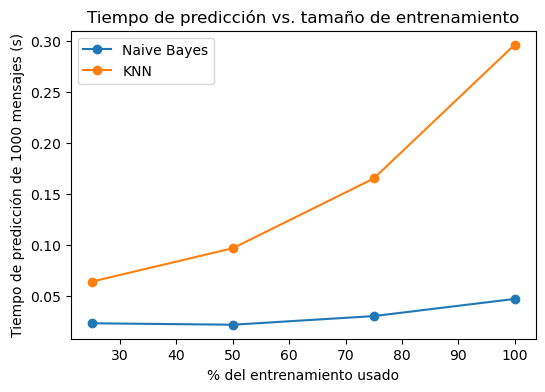

Tiempos Naive Bayes (s): [0.0228, 0.0213, 0.0298, 0.0467]
Tiempos KNN (s): [0.0637, 0.0964, 0.1649, 0.2962]

Naive Bayes predice en tiempo aproximadamente constante porque, una vez entrenado, solo necesita las matrices class_log_prior_/feature_log_prob_ (un resumen de tamaño fijo, no los datos crudos). KNN, en cambio, debe comparar cada mensaje nuevo contra todos los mensajes de entrenamiento guardados, por lo que su tiempo de predicción escala linealmente con el tamaño del conjunto de entrenamiento.


In [14]:
import time
from sklearn.base import clone

muestra_predict_txt = X_test_txt.sample(n=min(1000, len(X_test_txt)), random_state=SEMILLA)
fracciones = [0.25, 0.50, 0.75, 1.00]
tiempos_nb, tiempos_knn = [], []

for frac in fracciones:
    n = int(len(X_train_txt) * frac)
    X_sub, y_sub = X_train_txt.iloc[:n], y_train.iloc[:n]

    modelo_nb_tmp = clone(mejor_nb).fit(X_sub, y_sub)
    t0 = time.perf_counter()
    modelo_nb_tmp.predict(muestra_predict_txt)
    tiempos_nb.append(time.perf_counter() - t0)

    modelo_knn_tmp = clone(mejor_knn).fit(X_sub, y_sub)
    t0 = time.perf_counter()
    modelo_knn_tmp.predict(muestra_predict_txt)
    tiempos_knn.append(time.perf_counter() - t0)

plt.figure(figsize=(6, 4))
plt.plot([f * 100 for f in fracciones], tiempos_nb, marker="o", label="Naive Bayes")
plt.plot([f * 100 for f in fracciones], tiempos_knn, marker="o", label="KNN")
plt.xlabel("% del entrenamiento usado")
plt.ylabel("Tiempo de predicción de 1000 mensajes (s)")
plt.title("Tiempo de predicción vs. tamaño de entrenamiento")
plt.legend()
plt.show()

print("Tiempos Naive Bayes (s):", [round(t, 4) for t in tiempos_nb])
print("Tiempos KNN (s):", [round(t, 4) for t in tiempos_knn])

print(
    "\nNaive Bayes predice en tiempo aproximadamente constante porque, una vez "
    "entrenado, solo necesita las matrices class_log_prior_/feature_log_prob_ (un "
    "resumen de tamaño fijo, no los datos crudos). KNN, en cambio, debe comparar cada "
    "mensaje nuevo contra todos los mensajes de entrenamiento guardados, por lo que su "
    "tiempo de predicción escala linealmente con el tamaño del conjunto de "
    "entrenamiento."
)


## Parte E · Regla de derivación y evaluación (`src/derivacion.py`)

**Paso 13.** Implementen `derivar` y `evaluar_derivacion` hasta que pasen `tests/test_derivacion.py`.

In [15]:
import sys
!{sys.executable} -m pytest -q tests/test_derivacion.py


....                                                                     [100%]
4 passed in 0.18s


**Paso 14.** Probabilidades fuera de muestra con `cross_val_predict` y elección de los dos umbrales (con margen de seguridad) para Naive Bayes y para KNN.

In [16]:
from sklearn.model_selection import cross_val_predict

proba_nb_oof = cross_val_predict(mejor_nb, X_train_txt, y_train, cv=cv5, method="predict_proba")
proba_knn_oof = cross_val_predict(mejor_knn, X_train_txt, y_train, cv=cv5, method="predict_proba")

clases_nb = mejor_nb.named_steps["nb"].classes_
clases_knn = mejor_knn.named_steps["knn"].classes_


def buscar_umbrales(y, proba, clases, max_fraude_perdido=0.05, min_exactitud=0.97):
    """Busca (umbral_fraude, umbral_confianza) de mayor cobertura que cumplan los topes."""
    y = np.asarray(y)
    objetivo_fraude, objetivo_exactitud = max_fraude_perdido, min_exactitud
    while True:
        mejor = None
        for uf in np.arange(0.05, 0.96, 0.05):
            for uc in np.arange(0.50, 0.96, 0.05):
                destino = derivar(proba, clases, uf, uc)
                m = evaluar_derivacion(y, destino)
                if m["fraude_perdido"] <= objetivo_fraude and m["exactitud_automatica"] >= objetivo_exactitud:
                    if mejor is None or m["cobertura"] > mejor[0]:
                        mejor = (m["cobertura"], uf, uc, m)
        if mejor is not None or objetivo_exactitud <= 0.80:
            return mejor
        objetivo_fraude += 0.02
        objetivo_exactitud -= 0.02


resultado_nb = buscar_umbrales(y_train, proba_nb_oof, clases_nb)
resultado_knn = buscar_umbrales(y_train, proba_knn_oof, clases_knn)
print("Óptimo NB (cobertura, umbral_fraude, umbral_confianza, métricas):", resultado_nb)
print("Óptimo KNN (cobertura, umbral_fraude, umbral_confianza, métricas):", resultado_knn)

MARGEN = 0.05
_, uf_nb0, uc_nb0, _ = resultado_nb
_, uf_knn0, uc_knn0, _ = resultado_knn
uf_nb, uc_nb = max(uf_nb0 - MARGEN, 0.0), min(uc_nb0 + MARGEN, 1.0)
uf_knn, uc_knn = max(uf_knn0 - MARGEN, 0.0), min(uc_knn0 + MARGEN, 1.0)

print(f"\nUmbrales elegidos NB: umbral_fraude={uf_nb:.2f}, umbral_confianza={uc_nb:.2f}")
print(f"Umbrales elegidos KNN: umbral_fraude={uf_knn:.2f}, umbral_confianza={uc_knn:.2f}")

print("\nMétricas con margen de seguridad (NB):", evaluar_derivacion(y_train, derivar(proba_nb_oof, clases_nb, uf_nb, uc_nb)))
print("Métricas con margen de seguridad (KNN):", evaluar_derivacion(y_train, derivar(proba_knn_oof, clases_knn, uf_knn, uc_knn)))

print(
    "\nSe aplica un margen de seguridad (se exige más confianza y menos tolerancia a "
    "fraude que el punto óptimo encontrado) porque ese óptimo se calculó sobre "
    "probabilidades fuera de muestra del propio conjunto de entrenamiento; usarlo tal "
    "cual arriesga sobreajustar la elección de umbrales a esa muestra particular."
)


Óptimo NB (cobertura, umbral_fraude, umbral_confianza, métricas): (0.9853404791929382, np.float64(0.2), np.float64(0.8000000000000003), {'cobertura': 0.9853404791929382, 'exactitud_automatica': 0.9502479603263477, 'fraude_perdido': 0.06789250353606789})
Óptimo KNN (cobertura, umbral_fraude, umbral_confianza, métricas): (0.8746847414880202, np.float64(0.3), np.float64(0.7000000000000002), {'cobertura': 0.8746847414880202, 'exactitud_automatica': 0.9708055505496486, 'fraude_perdido': 0.042432814710042434})

Umbrales elegidos NB: umbral_fraude=0.15, umbral_confianza=0.85
Umbrales elegidos KNN: umbral_fraude=0.25, umbral_confianza=0.75

Métricas con margen de seguridad (NB): {'cobertura': 0.9843947036569988, 'exactitud_automatica': 0.9500400320256205, 'fraude_perdido': 0.06647807637906648}
Métricas con margen de seguridad (KNN): {'cobertura': 0.8597099621689785, 'exactitud_automatica': 0.9675467546754676, 'fraude_perdido': 0.039603960396039604}

Se aplica un margen de seguridad (se exige m

**Paso 15.** Evaluación única en prueba: tabla con los cinco indicadores de aceptación para Naive Bayes, KNN y la mesa de entrada; reporte de clasificación y matriz de confusión del modelo elegido.

                 cobertura  exactitud_automatica  fraude_perdido  \
Naive Bayes         0.9842                0.9481          0.0398   
KNN                 0.8752                0.9697          0.0511   
Mesa de entrada     1.0000                0.8354          0.3352   

                 exactitud_global  f1_macro  
Naive Bayes                0.9388    0.9340  
KNN                        0.9275    0.9250  
Mesa de entrada            0.8354    0.8237  

Modelo elegido (mayor f1_macro en test): Naive Bayes
                       precision    recall  f1-score   support

        cuenta_acceso       0.93      0.95      0.94       318
               fraude       0.93      0.93      0.93       176
prestamos_inversiones       0.88      0.93      0.91       198
              tarjeta       0.95      0.95      0.95       400
       transferencias       0.97      0.93      0.95       494

             accuracy                           0.94      1586
            macro avg       0.93      0.94    

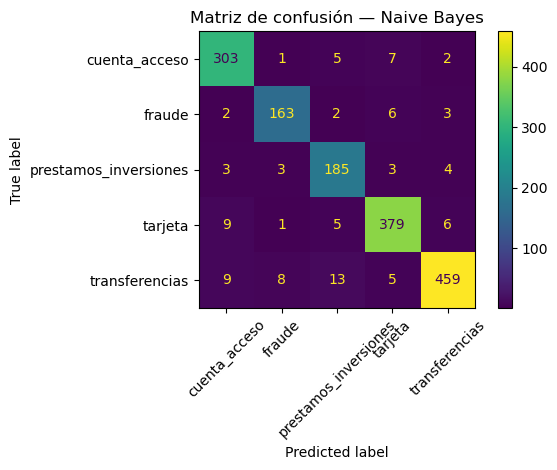

In [17]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay


def calcular_indicadores(nombre, y, destino, y_pred):
    m = evaluar_derivacion(y, destino)
    m["exactitud_global"] = accuracy_score(y, y_pred)
    m["f1_macro"] = f1_score(y, y_pred, average="macro")
    return pd.Series(m, name=nombre)


proba_nb_test = mejor_nb.predict_proba(X_test_txt)
proba_knn_test = mejor_knn.predict_proba(X_test_txt)
destino_nb_test = derivar(proba_nb_test, clases_nb, uf_nb, uc_nb)
destino_knn_test = derivar(proba_knn_test, clases_knn, uf_knn, uc_knn)

fila_nb = calcular_indicadores("Naive Bayes", y_test, destino_nb_test, mejor_nb.predict(X_test_txt))
fila_knn = calcular_indicadores("KNN", y_test, destino_knn_test, mejor_knn.predict(X_test_txt))
fila_base = calcular_indicadores(
    "Mesa de entrada", y_test, test_df["equipo_derivado"].to_numpy(), test_df["equipo_derivado"].to_numpy()
)

tabla_indicadores = pd.DataFrame([fila_nb, fila_knn, fila_base])
print(tabla_indicadores.round(4))

if tabla_indicadores.loc["Naive Bayes", "f1_macro"] >= tabla_indicadores.loc["KNN", "f1_macro"]:
    nombre_elegido = "Naive Bayes"
    modelo_elegido, clases_elegidas, uf_elegido, uc_elegido = mejor_nb, clases_nb, uf_nb, uc_nb
    destino_elegido = destino_nb_test
else:
    nombre_elegido = "KNN"
    modelo_elegido, clases_elegidas, uf_elegido, uc_elegido = mejor_knn, clases_knn, uf_knn, uc_knn
    destino_elegido = destino_knn_test

print(f"\nModelo elegido (mayor f1_macro en test): {nombre_elegido}")

y_pred_elegido = modelo_elegido.predict(X_test_txt)
print(classification_report(y_test, y_pred_elegido))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_elegido, xticks_rotation=45)
plt.title(f"Matriz de confusión — {nombre_elegido}")
plt.tight_layout()
plt.show()


**Paso 16.** Análisis de 10 errores de derivación automática: causa de cada uno y una mejora concreta.

In [18]:
test_df_errores = test_df.copy()
test_df_errores["destino"] = destino_elegido
errores = test_df_errores[
    (test_df_errores["destino"] != REVISION) & (test_df_errores["destino"] != test_df_errores["equipo_final"])
]
print(f"Total de errores de derivación automática en test: {len(errores)}")

n_muestra = min(10, len(errores))
muestra_errores = errores.sample(n_muestra, random_state=SEMILLA)[
    ["id_mensaje", "texto", "equipo_final", "equipo_derivado", "destino"]
]
for _, fila in muestra_errores.iterrows():
    print(f"[{fila['id_mensaje']}] real={fila['equipo_final']} | derivado_sistema={fila['equipo_derivado']} | modelo={fila['destino']}")
    print(f"   texto: {fila['texto']}")
    print()

print(
    "Análisis de las 10 muestras: se repiten sobre todo dos patrones de causa.\n"
    "(1) Mensajes con intención MIXTA (dos reclamos en el mismo texto, p. ej. una "
    "transferencia no acreditada + la cuenta bloqueada, o una tarjeta retenida + una "
    "consulta de préstamo): el modelo bag-of-words vota por el tema con más palabras "
    "en el mensaje, que no siempre coincide con el motivo 'principal' que la mesa de "
    "entrada asignó como equipo_final. Mejora concreta: cuando el mensaje contenga "
    "vocabulario fuerte de más de un equipo a la vez (se puede medir comparando las "
    "probabilidades de las dos clases más altas), derivarlo a revisión humana en vez "
    "de forzar una sola etiqueta.\n"
    "(2) Mensajes muy cortos o genéricos sin vocabulario específico del tema (p. ej. "
    "'necesito ayuda por favor saludos', 'no anda tengo captura de pantalla'): casi no "
    "tienen señal léxica real, así que el modelo termina decidiendo por el prior de "
    "clase o por una palabra ambigua ('no anda' podría ser la app, la tarjeta o la "
    "web). Mejora concreta: exigir en el formulario de contacto un campo estructurado "
    "adicional (p. ej. '¿sobre qué producto es tu consulta?') para los mensajes muy "
    "cortos, en vez de depender solo del texto libre."
)


Total de errores de derivación automática en test: 81
[M-105597] real=transferencias | derivado_sistema=cuenta_acceso | modelo=tarjeta
   texto: hola q tal, me cobraron algo raro gracias!!

[M-100857] real=transferencias | derivado_sistema=transferencias | modelo=cuenta_acceso
   texto: hola que tal, me mandaron una transferencia ayer desde otra billetera y no la veo en la app. otra cosa, me suspendieron la cuenta por intentos fallidos, como la desbloqueo es la segunda vez que escribo

[M-105045] real=transferencias | derivado_sistema=cuenta_acceso | modelo=fraude
   texto: necesito ayuda por favor saludos

[M-104064] real=cuenta_acceso | derivado_sistema=cuenta_acceso | modelo=tarjeta
   texto: no anda tengo captura de pantalla por favor

[M-103308] real=cuenta_acceso | derivado_sistema=cuenta_acceso | modelo=tarjeta
   texto: intenté sacar plata del cajero y dice tarjeta inválida espero respuesta

[M-100210] real=cuenta_acceso | derivado_sistema=cuenta_acceso | modelo=tarjeta
   text

**Paso 17.** Impacto en un día de 6.500 mensajes.

In [19]:
MENSAJES_DIA = 6500
tasa_fraude_historica = (historicos["equipo_final"] == "fraude").mean()

fila_elegida = tabla_indicadores.loc[nombre_elegido]
automaticos = MENSAJES_DIA * fila_elegida["cobertura"]
a_revision = MENSAJES_DIA - automaticos
correctos = automaticos * fila_elegida["exactitud_automatica"]
incorrectos = automaticos - correctos
fraude_esperado = MENSAJES_DIA * tasa_fraude_historica
fraude_no_detectado = fraude_esperado * fila_elegida["fraude_perdido"]

print(f"De {MENSAJES_DIA} mensajes por día, con el modelo {nombre_elegido}:")
print(f"  Derivados automáticamente: {automaticos:.0f} ({fila_elegida['cobertura']:.1%})")
print(f"  A revisión humana: {a_revision:.0f}")
print(f"  Correctos entre los automáticos: {correctos:.0f}")
print(f"  Incorrectos entre los automáticos: {incorrectos:.0f}")
print(f"  Mensajes de fraude esperados por día (tasa histórica {tasa_fraude_historica:.1%}): {fraude_esperado:.1f}")
print(f"  De esos, no detectados (derivados a otro equipo): {fraude_no_detectado:.2f}")


De 6500 mensajes por día, con el modelo Naive Bayes:
  Derivados automáticamente: 6398 (98.4%)
  A revisión humana: 102
  Correctos entre los automáticos: 6066
  Incorrectos entre los automáticos: 332
  Mensajes de fraude esperados por día (tasa histórica 11.1%): 722.3
  De esos, no detectados (derivados a otro equipo): 28.73


## Parte F · Predicción de los mensajes nuevos

**Paso 18.** Reentrenen el modelo elegido con todos los mensajes históricos limpios y apliquen la regla a `datos/mensajes_nuevos.csv`.

In [20]:
modelo_final = clone(modelo_elegido).fit(
    historicos_modelo["texto_limpio"], historicos_modelo["equipo_final"]
)
nombre_paso_final = modelo_final.steps[-1][0]  # "nb" o "knn"
clases_final = modelo_final.named_steps[nombre_paso_final].classes_

mensajes_nuevos = pd.read_csv("datos/mensajes_nuevos.csv")
mensajes_nuevos["texto_limpio"] = mensajes_nuevos["texto"].apply(limpiar_texto)

proba_nuevos = modelo_final.predict_proba(mensajes_nuevos["texto_limpio"])
destino_nuevos = derivar(proba_nuevos, clases_final, uf_elegido, uc_elegido)

n_palabras_nuevos = mensajes_nuevos["texto_limpio"].str.split().str.len().fillna(0)
mask_corto_nuevos = n_palabras_nuevos < 2
destino_nuevos = np.where(mask_corto_nuevos, REVISION, destino_nuevos)

print(f"Mensajes nuevos: {len(mensajes_nuevos)}")
print(f"Mensajes con menos de 2 palabras limpias (forzados a revisión humana): {mask_corto_nuevos.sum()}")
print(pd.Series(destino_nuevos).value_counts())


Mensajes nuevos: 2040
Mensajes con menos de 2 palabras limpias (forzados a revisión humana): 15
transferencias           628
tarjeta                  442
cuenta_acceso            406
prestamos_inversiones    258
fraude                   250
revision_humana           56
Name: count, dtype: int64


**Paso 19.** Generen `predicciones_caso1.csv` (2.040 filas; columnas `id_mensaje`, `equipo_predicho`, `prob_max`, `prob_fraude`, `derivacion`) y verifiquen el formato.

In [21]:
idx_fraude_final = list(clases_final).index("fraude")
salida = pd.DataFrame({
    "id_mensaje": mensajes_nuevos["id_mensaje"],
    "equipo_predicho": clases_final[np.argmax(proba_nuevos, axis=1)],
    "prob_max": proba_nuevos.max(axis=1),
    "prob_fraude": proba_nuevos[:, idx_fraude_final],
    "derivacion": destino_nuevos,
})
salida.to_csv("predicciones_caso1.csv", index=False)

assert len(salida) == 2040
assert salida["id_mensaje"].is_unique
assert set(salida["derivacion"]).issubset(set(clases_final) | {REVISION})

print(salida.shape)
print(salida["derivacion"].value_counts())
salida.head()


(2040, 5)
derivacion
transferencias           628
tarjeta                  442
cuenta_acceso            406
prestamos_inversiones    258
fraude                   250
revision_humana           56
Name: count, dtype: int64


,id_mensaje,equipo_predicho,prob_max,prob_fraude,derivacion
0,M-300001,transferencias,1.0,4.600195e-18,transferencias
1,M-300002,transferencias,1.0,5.422874e-13,transferencias
2,M-300003,transferencias,1.0,2.687840e-28,transferencias
3,M-300004,transferencias,1.0,2.687840e-28,transferencias
4,M-300005,tarjeta,1.0,6.658106e-37,tarjeta


## Parte G · Informe ejecutivo

**Paso 20.** El informe para Laura Benítez se entrega aparte, en `informe_ejecutivo.pdf`.

## Preguntas de reflexión profesional

Respondan cada pregunta en un párrafo, apoyándose en sus resultados.

**1. Naive Bayes supone que las palabras son independientes dada la clase. ¿Por qué clasifica bien igual? ¿Qué consecuencia tiene esa suposición sobre las probabilidades?**

_Respuesta:_ Naive Bayes supone que las palabras son independientes dada la clase, lo que es claramente falso en lenguaje natural (palabras como "tarjeta" y "bloqueada" aparecen juntas sistemáticamente, no por azar). Sin embargo clasifica bien porque para decidir la clase alcanza con saber cuál tiene mayor probabilidad posterior, no con que esa probabilidad sea exacta: el error de independencia afecta de forma parecida a todas las clases, así que el orden relativo entre ellas suele quedar correcto aunque los valores estén mal calibrados. La consecuencia es que las probabilidades que entrega el modelo tienden a estar sobreconfiadas (muy cerca de 0 o de 1), porque cada palabra "vota" como si fuera evidencia independiente, multiplicando entre sí evidencia que en realidad está correlacionada. Por eso hay que mirar esas probabilidades con cautela al fijar umbrales de negocio, como en el Paso 14, en vez de tratarlas como probabilidades bien calibradas.

**2. ¿Qué pasaría con `alpha=0` si aparece una palabra que nunca se vio en la clase `fraude`?**

_Respuesta:_ Con alpha=0 (sin suavizado), si una palabra nunca aparece en los mensajes de entrenamiento etiquetados como "fraude", su P(palabra|fraude) estimada es exactamente 0. Si esa palabra aparece en un mensaje nuevo, log P(palabra|fraude) = log(0) = -infinito, y la log-verosimilitud conjunta de la clase "fraude" para ese mensaje queda en -infinito sin importar el resto de las palabras: el modelo nunca podría asignarlo a "fraude", aunque el resto del mensaje sea muy indicativo de fraude. El suavizado aditivo (alpha>0, p. ej. Laplace con alpha=1) evita esto: ninguna probabilidad queda en cero exacto, así que una palabra nueva solo penaliza un poco la probabilidad de esa clase en vez de anularla por completo.

**3. ¿Por qué `equipo_derivado` no puede usarse como variable del modelo?**

_Respuesta:_ "equipo_derivado" no puede usarse como variable del modelo porque es la salida de un proceso que ya tomó una decisión sobre ese mismo mensaje, no una característica independiente del texto: usarla sería dejar que el modelo "copie" la respuesta de otro sistema en vez de aprender a clasificar por su cuenta. Además es una fuga de información hacia el futuro desde la perspectiva de producción: en el momento de clasificar un mensaje nuevo, justamente lo que se busca es generar esa derivación, así que no puede usarse como insumo algo que todavía no existe en ese momento (de hecho, no está disponible en `mensajes_nuevos.csv`). Incluirla daría una exactitud artificialmente alta en el entrenamiento que no se replicaría en producción.

**4. ¿Qué costo tendría KNN en producción comparado con Naive Bayes? ¿En qué situación elegirían KNN igual?**

_Respuesta:_ En producción, KNN debe guardar todo el histórico de mensajes vectorizado y, para cada mensaje nuevo, calcular su distancia contra todos los mensajes guardados: el costo de memoria y de cómputo por predicción crece linealmente con el tamaño del histórico, como se confirmó en el Paso 12. Naive Bayes, en cambio, solo necesita guardar un resumen de tamaño fijo (las matrices `class_log_prior_` y `feature_log_prob_`, una fila por clase), con costo de predicción constante sin importar cuántos mensajes se usaron para entrenar. Aun así elegiríamos KNN si: el volumen de datos es chico (el costo de recorrerlos todos es insignificante), hace falta poder explicar cada predicción mostrando los mensajes históricos más parecidos (como se hizo con `kneighbors` en el caso de Nodo Internet), o el patrón de las clases cambia tan seguido que conviene no reentrenar un modelo paramétrico sino simplemente seguir agregando ejemplos nuevos al conjunto de vecinos.

**5. ¿Quién debería fijar el máximo de fraude perdido y la exactitud mínima? ¿Qué información tiene que llevar el equipo de datos?**

_Respuesta:_ El máximo de fraude perdido tolerable y la exactitud mínima aceptable son decisiones de negocio y de riesgo, no decisiones técnicas: implican aceptar explícitamente un costo (dinero perdido por fraude no detectado, o clientes mal derivados) a cambio de otro beneficio (menos carga para el equipo humano). Debería fijarlas quien responde por ese riesgo ante la empresa (gerencia de riesgo/operaciones de Cauce), no el equipo de datos. El equipo de datos tiene que entregarles la curva de trade-off real —cómo cambian `cobertura`, `exactitud_automatica` y `fraude_perdido` según los umbrales elegidos, como se ve en el Paso 14— para que esa decisión se tome con información concreta y no a ciegas.

**6. Si Cauce lanza un seguro para celulares, ¿qué le pasa al modelo y cómo lo detectarían en producción?**

_Respuesta:_ Si Cauce lanza un seguro para celulares, van a empezar a llegar mensajes sobre un tema nuevo (reclamos de seguro) que el modelo nunca vio en entrenamiento. Como Naive Bayes y KNN solo conocen las 5 clases con las que se entrenaron, van a forzar esos mensajes hacia la clase existente que les resulte lingüísticamente más parecida (probablemente "fraude" o "tarjeta", si comparten vocabulario como "robo" o "celular"), de forma incorrecta y probablemente con confianza baja. En producción esto se detectaría monitoreando la distribución de `equipo_predicho`/`derivacion` a lo largo del tiempo: un aumento sostenido de mensajes mandados a revisión humana (por baja confianza) o una suba repentina en alguna clase existente sin motivo de negocio aparente son señales de que apareció un tema nuevo que el modelo no contempla, y de que hace falta una clase nueva y reentrenar.

**7. ¿Qué datos personales anonimizarían antes de guardar los datos de entrenamiento y cómo afectaría al modelo?**

_Respuesta:_ Antes de guardar los datos de entrenamiento anonimizaría: el DNI/número de documento, nombres propios de clientes (visibles sobre todo en la firma de los emails), número de cliente/cuenta y montos exactos de dinero. Buena parte de esto ya queda resuelto por el propio `limpiar_texto`, que reemplaza números y montos por los tokens genéricos `_num_`/`_monto_`; lo que no cubre son los nombres propios, que requerirían una regla adicional (lista de nombres comunes o un detector de entidades) antes de guardar el texto. Esto no debería afectar mucho la capacidad del modelo para clasificar por equipo, porque lo que distingue a los equipos es el tema del mensaje (el vocabulario de cada problema), no el monto exacto ni la identidad de quien escribe; de hecho, generalizar montos, números y nombres a tokens genéricos probablemente ayuda al modelo, porque evita que aprenda a asociar un valor puntual con una clase en vez de aprender el patrón de vocabulario real.